# 03 — Gradients, including at the poles

Gradients of a waveform with respect to its parameters are needed for gradient-based
sampling (HMC/NUTS), optimization, and Fisher-matrix estimates.  `wigner_D`, `sYlm`,
`rotate` and `evaluate` can all be differentiated with respect to the rotor (and the
modes), in forward and reverse mode, to any order.

This notebook covers:

1. Why plain automatic differentiation fails at the poles $\beta = 0, \pi$
2. The fix: exact derivatives from the Lie algebra of rotations
3. Derivatives with respect to the observer direction and Euler angles
4. Second derivatives, and a Fisher matrix for a face-on observer
5. Cost
6. What not to differentiate

In [1]:
import time

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import spherical
from spherical import jaxwigner as jw
from spherical.jaxwigner import modes as jw_modes

rng = np.random.default_rng(3)
ell_max, s = 4, -2
f = rng.normal(size=spherical.Ysize(0, ell_max)) + 1j * rng.normal(size=spherical.Ysize(0, ell_max))
f[: spherical.Yindex(2, -2)] = 0
f = jnp.asarray(f)

def central_difference(fun, x, h=1e-6):
    return (fun(x + h) - fun(x - h)) / (2 * h)

## 1. The problem

Internally, 𝔇 is computed from $\sin\beta$ and the phases $e^{i\alpha}$ and $e^{i\gamma}$.  At
the poles, $\beta = 0$ or $\pi$, one combination of $\alpha$ and $\gamma$ is undefined.  The
singular pieces cancel in the **values**, which are exact everywhere, but not in their
**derivatives**: differentiating the implementation directly gives wrong answers at the
poles, and loses accuracy near them.

The poles are not exotic.  An observer on the $z$ axis (a face-on binary, $\theta = 0$) and
the identity rotation (a frame that starts aligned) both sit exactly on them.

Below, $f(\theta) = \texttt{evaluate}(f_{\ell m}, R(\theta, \phi=0.3))$ is differentiated with
respect to $\theta$ three ways: plain automatic differentiation of the implementation (kept
available as `jw_modes._evaluate.fun` for exactly this comparison), the package's own
derivative, and finite differences.

In [2]:
def value(θ, evaluate):
    return evaluate(f, jw.from_spherical_coordinates(θ, 0.3), s)

plain = lambda θ: value(θ, lambda f, R, s: jw_modes._evaluate.fun(f, R, s, 0))
package = lambda θ: value(θ, jw.evaluate)

for θ in (0.5, 1e-3, 0.0, np.pi):
    print(f"θ = {θ:<6.4g}  plain autodiff: {complex(jax.jacfwd(plain)(θ)):.6f}   "
          f"package: {complex(jax.jacfwd(package)(θ)):.6f}   "
          f"finite difference: {complex(central_difference(package, θ)):.6f}")

θ = 0.5     plain autodiff: -2.359633-0.718852j   package: -2.359633-0.718852j   finite difference: -2.359633-0.718852j
θ = 0.001   plain autodiff: 2.336039+2.964891j   package: 2.336039+2.964891j   finite difference: 2.336039+2.964891j
θ = 0       plain autodiff: 0.000000+0.000000j   package: 2.340308+2.963109j   finite difference: 2.340308+2.963109j


θ = 3.142   plain autodiff: -4.075533-3.875205j   package: -3.499928-0.536739j   finite difference: -3.499928-0.536739j


Close to the pole, plain differentiation gives finite but inaccurate results: it subtracts two
large terms of size $\sim 1/\sin\beta$ to get an $O(1)$ answer.  The package's derivative stays
accurate all the way to the pole:

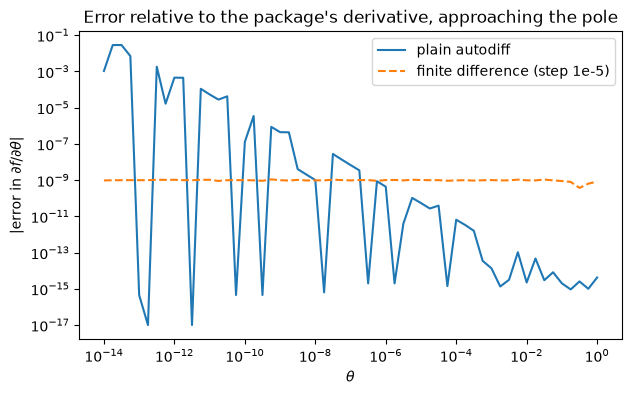

In [3]:
θs = np.logspace(-14, 0, 57)
reference = np.array([complex(jax.jacfwd(package)(θ)) for θ in θs])
plain_error = np.abs(np.array([complex(jax.jacfwd(plain)(θ)) for θ in θs]) - reference)
fd_error = np.abs(np.array([complex(central_difference(package, θ, 1e-5)) for θ in θs]) - reference)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(θs, plain_error + 1e-17, label="plain autodiff")
ax.loglog(θs, fd_error + 1e-17, label="finite difference (step 1e-5)", ls="--")
ax.set(xlabel=r"$\theta$", ylabel=r"|error in $\partial f/\partial\theta$|",
       title="Error relative to the package's derivative, approaching the pole")
ax.legend()
plt.show()

## 2. The fix: derivatives from the rotation group

𝔇 itself is a smooth function of the quaternion; only the way it is computed has trouble at
the poles.  Its derivative follows from the representation property
$\mathfrak{D}(R_1 R_2) = \mathfrak{D}(R_1)\mathfrak{D}(R_2)$.  A small change $\delta R$ can be written as

$$
R + \epsilon\,\delta R = (1 + \epsilon\sigma)\, R\, e^{\epsilon\omega},
\qquad \sigma + \omega = \bar R\,\delta R / |R|^2,
$$

with $\sigma$ a scalar (a change of normalization, which does not affect 𝔇) and $\omega$ a
vector.  Then

$$
\delta\mathfrak{D}^\ell = \mathfrak{D}^\ell(R)\, G^\ell, \qquad
G^\ell = 2\,(\omega_x \Lambda^\ell_x + \omega_y \Lambda^\ell_y + \omega_z \Lambda^\ell_z),
$$

where the $\Lambda^\ell_k$ are fixed **tridiagonal** matrices (angular-momentum generators in
this package's conventions).  For the harmonics, ${}_sY_{\ell m} \propto \mathfrak{D}^\ell_{m,-s}$,
multiplying by $G$ mixes in the neighbouring spin weights $s\pm1$ — the familiar spin-raising
and lowering operators ð and ð̄.

These rules are attached to `wigner_D`, `sYlm`, `rotate` and `evaluate` with
`jax.custom_jvp`.  They are exact at every rotor, cost little more than the values, and are
linear in $\delta R$, so JAX derives reverse mode (`jax.grad`) from them automatically.
The rules call the functions they are attached to, so second and higher derivatives also
use them.  The details, with the explicit matrices, are in `spherical/jaxwigner/generators.py`.

The test suite (`tests/test_jaxwigner_gradients.py`) checks the rules three independent ways:
against plain autodiff away from the poles (where plain autodiff is valid), against finite
differences everywhere including the poles, and with JAX's `check_grads` to second order in
forward and reverse mode.

## 3. Derivatives with respect to angles

Rotors built inside JAX — with `jw.from_spherical_coordinates`, `jw.from_euler_angles`, and
`jw.multiply` — are smooth functions of their angles, so derivatives flow through them.  For
example, the gradient of $|h|^2$ with respect to the observer direction over the whole sphere,
poles included:

all gradients finite: True
∂|h|²/∂ϕ at θ = 0 and π (should vanish): 1.3628696045687061e-15


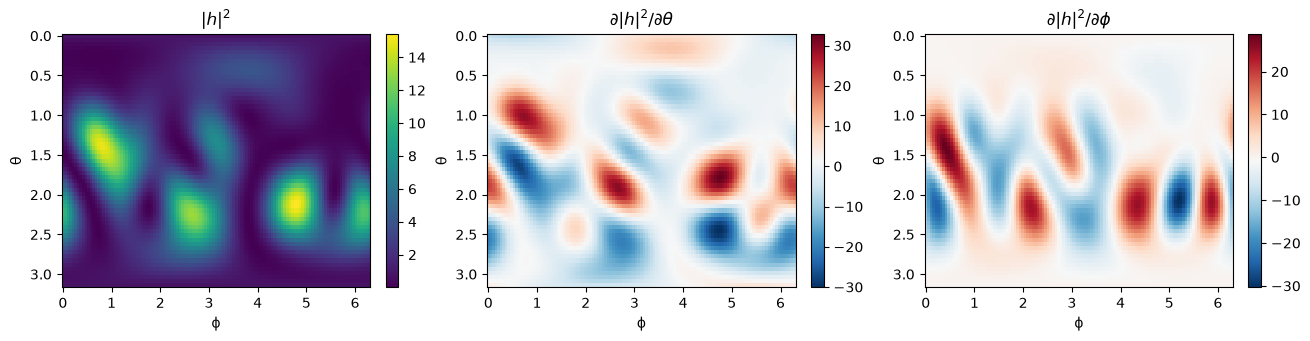

In [4]:
def power(θ, ϕ):
    return jnp.abs(jw.evaluate(f, jw.from_spherical_coordinates(θ, ϕ), s)) ** 2

θ = np.linspace(0, np.pi, 61)
ϕ = np.linspace(0, 2 * np.pi, 121)
Θ, Φ = np.meshgrid(θ, ϕ, indexing="ij")
grad_power = jax.jit(jax.vmap(jax.grad(power, argnums=(0, 1))))
dθ, dϕ = (g.reshape(Θ.shape) for g in grad_power(Θ.ravel(), Φ.ravel()))
P = jax.vmap(power)(Θ.ravel(), Φ.ravel()).reshape(Θ.shape)
print("all gradients finite:", bool(jnp.all(jnp.isfinite(dθ)) and jnp.all(jnp.isfinite(dϕ))))
print("∂|h|²/∂ϕ at θ = 0 and π (should vanish):", float(jnp.max(jnp.abs(dϕ[np.array([0, -1])]))))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), constrained_layout=True)
for ax, data, title in zip(axes, (P, dθ, dϕ), (r"$|h|^2$", r"$\partial|h|^2/\partial\theta$", r"$\partial|h|^2/\partial\phi$")):
    im = ax.pcolormesh(Φ, Θ, data, cmap="RdBu_r" if ax is not axes[0] else "viridis", shading="auto")
    ax.set(title=title, xlabel="ϕ", ylabel="θ")
    ax.invert_yaxis()
    fig.colorbar(im, ax=ax)
plt.show()

## 4. Second derivatives: a Fisher matrix on the pole

Using the toy precessing waveform of notebook 02, with four parameters — the observer's
inclination $\theta$ and azimuth $\phi$, the precession cone's opening angle $\beta_p$, and the
precession frequency $\Omega_p$ — the (white-noise) Fisher matrix is

$$
F_{ij} = \sum_t \mathrm{Re}\!\left[\partial_i h(t)\; \overline{\partial_j h(t)}\right].
$$

What matters is the rotor actually passed to `evaluate`, here $R(t)\,R_{\rm obs}$.  With a
precession cone of opening angle $\beta_p > 0$, that rotor is away from the poles even for a
face-on observer.  It sits **exactly on the pole** at every time sample when the observer is
face-on ($\theta = 0$) *and* the cone has zero opening angle ($\beta_p = 0$, the aligned-spin
limit) — a natural reference point to expand around.  That is where the Fisher matrix is
evaluated below.  (At $\beta_p = 0$ the precession frequency has no effect, so the $\Omega_p$
row and column vanish.)

This is a toy example of the mechanics only, not a physical waveform model.

In [5]:
T = 2000
t = jnp.linspace(0, 1, T)
Φ_orb = 2 * jnp.pi * (30 * t + 40 * t**2)
A = 1 + 2 * t**3
n = spherical.Ysize(0, 2)
h_cop = jnp.zeros((T, n), dtype=complex)
h_cop = h_cop.at[:, spherical.Yindex(2, 2)].set(A * jnp.exp(-2j * Φ_orb))
h_cop = h_cop.at[:, spherical.Yindex(2, -2)].set(A * jnp.exp(2j * Φ_orb))
h_cop = h_cop.at[:, spherical.Yindex(2, 1)].set(0.1 * A * jnp.exp(-1j * Φ_orb))
h_cop = h_cop.at[:, spherical.Yindex(2, -1)].set(-0.1 * A * jnp.exp(1j * Φ_orb))

def strain(params):
    θ, ϕ, β_p, Ω_p = params
    R_t = jw.from_euler_angles(Ω_p * t, β_p, -Ω_p * t)
    return jw.evaluate(h_cop, jw.multiply(R_t, jw.from_spherical_coordinates(θ, ϕ)), -2)

def fisher(params):
    J = jax.jacfwd(lambda p: jnp.stack([strain(p).real, strain(p).imag]))(params)  # (2, T, 4)
    return jnp.einsum("ati,atj->ij", J, J)

params = jnp.array([0.0, 0.3, 0.0, 2 * jnp.pi * 3])  # θ = 0, β_p = 0: on the pole
F = jax.jit(fisher)(params)
np.set_printoptions(precision=4, suppress=True)
print("Fisher matrix at θ = 0, β_p = 0:\n", np.asarray(F))

# Check entries with finite differences of the strain, which use only values
dh_dθ = central_difference(lambda θ: strain(params.at[0].set(θ)), 0.0)
dh_dβ = central_difference(lambda β: strain(params.at[2].set(β)), 0.0)
print("F[θ,θ] from finite differences:", float(jnp.sum(jnp.abs(dh_dθ) ** 2)))
print("F[θ,β_p] from finite differences:", float(jnp.sum((dh_dθ * jnp.conj(dh_dβ)).real)))

Fisher matrix at θ = 0, β_p = 0:
 [[  20.4724   -1.278    -0.188    -0.    ]
 [  -1.278  8188.9789   -1.1731   -0.    ]
 [  -0.188    -1.1731   20.4724    0.    ]
 [  -0.       -0.        0.        0.    ]]


F[θ,θ] from finite differences: 20.472447347654114
F[θ,β_p] from finite differences: -0.1879599927601657


For comparison, plain autodiff of the implementation gets the $\theta$ and $\beta_p$ derivatives
wrong at the pole (compare the first and third rows and columns):

In [6]:
def strain_plain(params):
    θ, ϕ, β_p, Ω_p = params
    R_t = jw.from_euler_angles(Ω_p * t, β_p, -Ω_p * t)
    return jw_modes._evaluate.fun(h_cop, jw.multiply(R_t, jw.from_spherical_coordinates(θ, ϕ)), -2, 0)

J_plain = jax.jacfwd(lambda p: jnp.stack([strain_plain(p).real, strain_plain(p).imag]))(params)
print("Fisher matrix from plain autodiff at θ = 0, β_p = 0 (wrong):\n", np.asarray(jnp.einsum("ati,atj->ij", J_plain, J_plain)))

Fisher matrix from plain autodiff at θ = 0, β_p = 0 (wrong):
 [[   0.        0.        0.        0.    ]
 [   0.     8188.9789    0.        0.    ]
 [   0.        0.        0.        0.    ]
 [   0.        0.        0.        0.    ]]


## 5. Cost

The derivative rules reuse the values already computed, plus (for harmonics) the harmonics of
spin weight $s\pm1$, which share the same $H$ wedge.  On this laptop's CPU, a value and its
gradient have cost between about 1.5× and 3.5× the value alone in different runs; CPU timings
here are noisy and only indicative.  GPU timings are a separate step.

In [7]:
T_big = 100_000
h_big = jnp.asarray(rng.normal(size=(T_big, 81)) + 1j * rng.normal(size=(T_big, 81)))
R_big = jnp.asarray(rng.normal(size=(T_big, 4)))

def loss(R, θ):
    return jnp.sum(jnp.abs(jw.evaluate(h_big, jw.multiply(R, jw.from_spherical_coordinates(θ, 0.3)), -2)) ** 2)

def timed(fn, *args, repeat=3):
    jax.block_until_ready(fn(*args))
    start = time.perf_counter()
    for _ in range(repeat):
        jax.block_until_ready(fn(*args))
    return (time.perf_counter() - start) / repeat * 1e3

value_only = timed(jax.jit(loss), R_big, 0.5)
value_and_gradient = timed(jax.jit(jax.value_and_grad(loss, argnums=(0, 1))), R_big, 0.5)
print(f"T = {T_big}, ℓ ≤ 8:  value {value_only:.0f} ms;  value and gradient {value_and_gradient:.0f} ms "
      f"({value_and_gradient / value_only:.2f}×)")

T = 100000, ℓ ≤ 8:  value 162 ms;  value and gradient 352 ms (2.17×)


## 6. What not to differentiate

- **`jw.euler_phases`** has no meaningful derivative at or near the poles, because the phases
  themselves are undefined there.  Differentiate `wigner_D`, `sYlm`, `rotate` or `evaluate`,
  which use it internally but carry their own exact derivative rules.
- **`jw.H_wedge` and `jw.wigner_d`** take $e^{i\beta}$ directly, and are smooth functions of
  $\beta$ everywhere, so they can be differentiated with ordinary autodiff.
- **Euler angles themselves are singular at the poles** as a parametrization: at $\beta = 0$,
  changing $\alpha$ and changing $\gamma$ produce the same rotation.  Derivatives with respect
  to Euler angles are correct, but a Fisher matrix in those coordinates is degenerate there.
  This is a property of the coordinates, not of the code.

## Summary

- Derivatives of `wigner_D`, `sYlm`, `rotate` and `evaluate` with respect to rotors are
  exact everywhere, including at $\beta = 0, \pi$, in forward and reverse mode and to any order.
- Derivatives flow through `jw.from_spherical_coordinates`, `jw.from_euler_angles` and
  `jw.multiply`, so gradients with respect to physical angles work directly.
- What matters is whether the rotor passed to a function is on a pole — for a precessing
  waveform, the composed rotor $R(t)R_{\rm obs}$ — not the observer direction alone.
- A value and its gradient cost a small multiple of the value alone (1.5–3.5× on CPU here).

Next: benchmarks on a GPU.